# Part 5: Advanced Matplotlib, Dashboards & Storytelling
**Course Notes Reference:** Parts 12 & 14

Topics covered:
1. Time-series rolling mean & marking special events (`axvline`)
2. Area (`fill_between`) and Stacked Area (`stackplot`) charts
3. Dual Axis (`twinx()`) — and when to use it carefully
4. Annotations & reference lines (`axhline`, `annotate`, `text`)
5. Error bars (`errorbar`) & Log scale (`yscale('log')`)
6. Building a 2x2 Dashboard Layout
7. Design Principles & Storytelling: Honest Axes (start at 0) vs Truncated Axes, Highlight-One-Grey-Rest


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("vgsales.csv").dropna(subset=["Year", "Publisher"]).copy()
df["Year"] = df["Year"].astype(int)


## 1. Time Series: Rolling Mean, Area & Stacked Area Plots


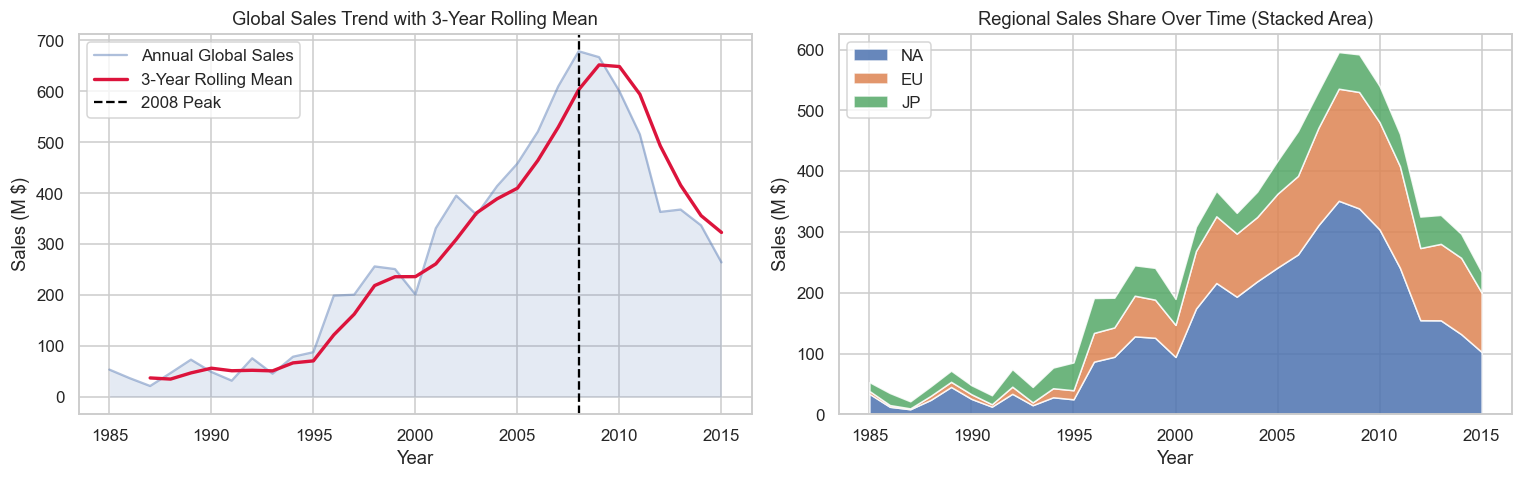

In [2]:
yearly = df.groupby("Year")[["NA_Sales", "EU_Sales", "JP_Sales", "Global_Sales"]].sum().sort_index()
yearly = yearly.loc[1985:2015]
rolling_3yr = yearly["Global_Sales"].rolling(window=3).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(yearly.index, yearly["Global_Sales"], alpha=0.45, label="Annual Global Sales")
axes[0].plot(yearly.index, rolling_3yr, color="crimson", linewidth=2.2, label="3-Year Rolling Mean")
axes[0].fill_between(yearly.index, yearly["Global_Sales"], alpha=0.15)
axes[0].axvline(2008, color="black", linestyle="--", label="2008 Peak")
axes[0].set_title("Global Sales Trend with 3-Year Rolling Mean")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Sales (M $)")
axes[0].legend()

axes[1].stackplot(
    yearly.index,
    yearly["NA_Sales"], yearly["EU_Sales"], yearly["JP_Sales"],
    labels=["NA", "EU", "JP"], alpha=0.85
)
axes[1].set_title("Regional Sales Share Over Time (Stacked Area)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Sales (M $)")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()


## 2. Dual Axis (`twinx`), Reference Lines & Annotations


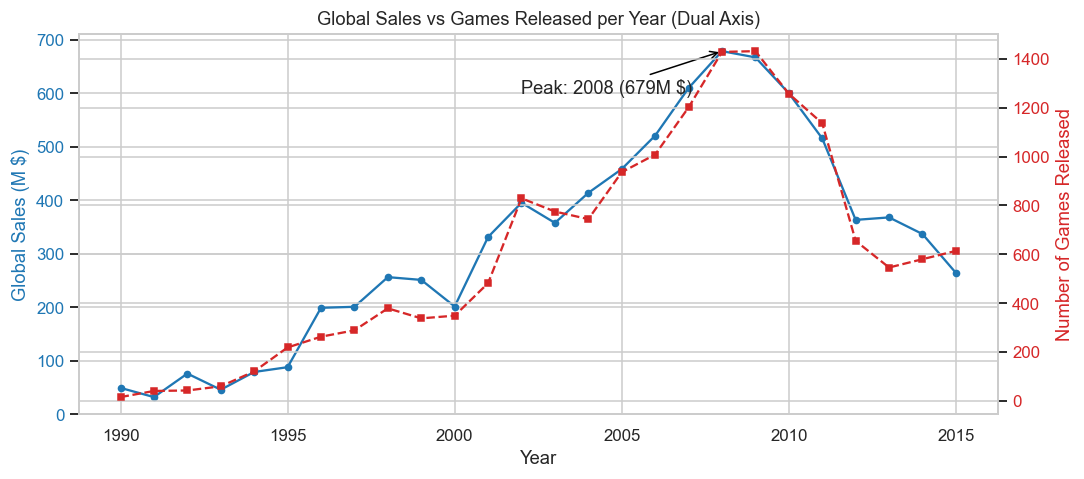

In [3]:
games_per_yr = df.groupby("Year").size().loc[1990:2015]
sales_per_yr = df.groupby("Year")["Global_Sales"].sum().loc[1990:2015]

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(sales_per_yr.index, sales_per_yr.values, color="tab:blue", marker="o", markersize=4, label="Total Sales")
ax1.set_xlabel("Year")
ax1.set_ylabel("Global Sales (M $)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(games_per_yr.index, games_per_yr.values, color="tab:red", linestyle="--", marker="s", markersize=4, label="Games Released")
ax2.set_ylabel("Number of Games Released", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

peak_yr = sales_per_yr.idxmax()
peak_val = sales_per_yr.max()
ax1.annotate(
    f"Peak: {peak_yr} ({peak_val:.0f}M $)",
    xy=(peak_yr, peak_val), xytext=(peak_yr - 6, peak_val - 80),
    arrowprops=dict(arrowstyle="->", color="black")
)
plt.title("Global Sales vs Games Released per Year (Dual Axis)")
plt.tight_layout()
plt.show()


## 3. Error Bars & Log Scale


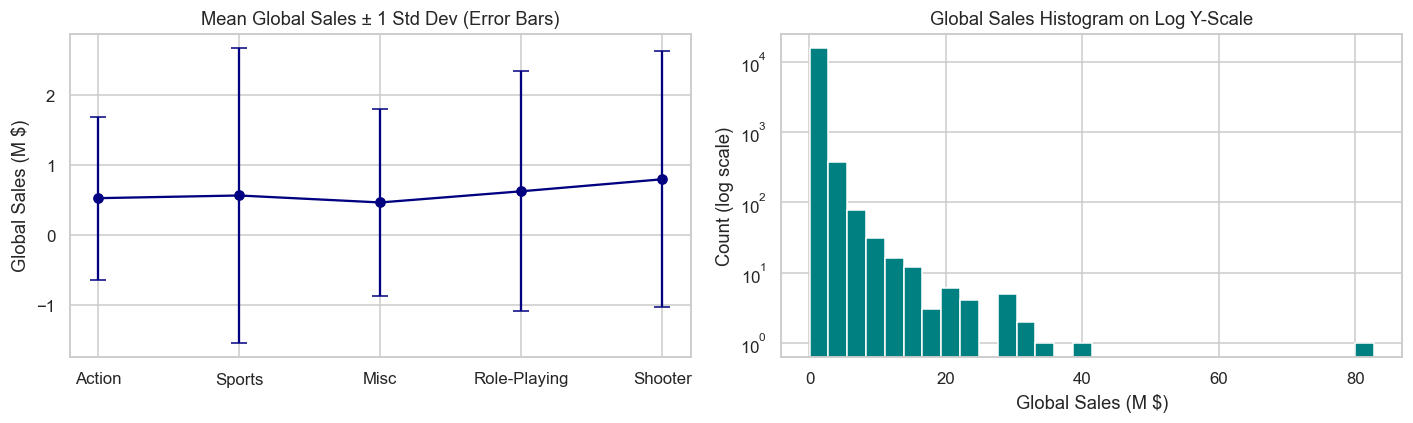

In [4]:
top5 = df["Genre"].value_counts().head(5).index
stats = df[df["Genre"].isin(top5)].groupby("Genre")["Global_Sales"].agg(["mean", "std"]).loc[top5]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(stats.index, stats["mean"], yerr=stats["std"], fmt="o-", capsize=5, color="navy")
axes[0].set_title("Mean Global Sales ± 1 Std Dev (Error Bars)")
axes[0].set_ylabel("Global Sales (M $)")

axes[1].hist(df["Global_Sales"], bins=30, color="teal", edgecolor="white")
axes[1].set_yscale("log")
axes[1].set_title("Global Sales Histogram on Log Y-Scale")
axes[1].set_xlabel("Global Sales (M $)")
axes[1].set_ylabel("Count (log scale)")

plt.tight_layout()
plt.show()


## 4. Complete 2x2 Overview Dashboard


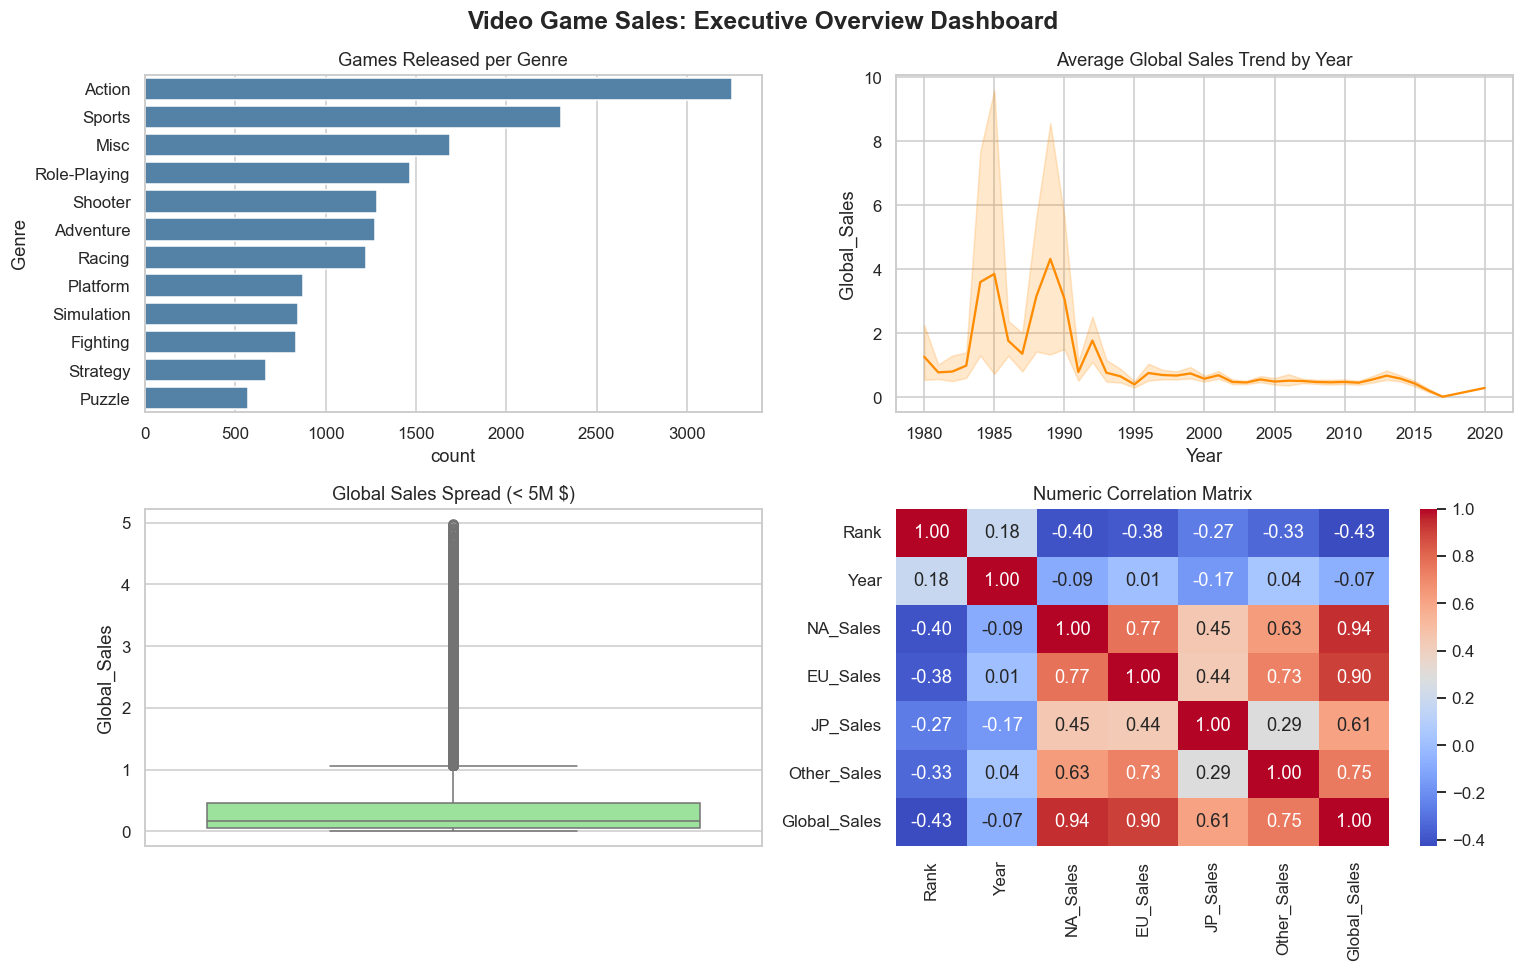

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

sns.countplot(y="Genre", data=df, ax=ax[0, 0], order=df["Genre"].value_counts().index, color="steelblue")
ax[0, 0].set_title("Games Released per Genre")

sns.lineplot(data=df, x="Year", y="Global_Sales", ax=ax[0, 1], color="darkorange")
ax[0, 1].set_title("Average Global Sales Trend by Year")

sns.boxplot(y="Global_Sales", data=df[df["Global_Sales"] < 5], ax=ax[1, 0], color="lightgreen")
ax[1, 0].set_title("Global Sales Spread (< 5M $)")

sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1, 1])
ax[1, 1].set_title("Numeric Correlation Matrix")

fig.suptitle("Video Game Sales: Executive Overview Dashboard", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Storytelling & Design Principles: Honest Axes vs Highlighting


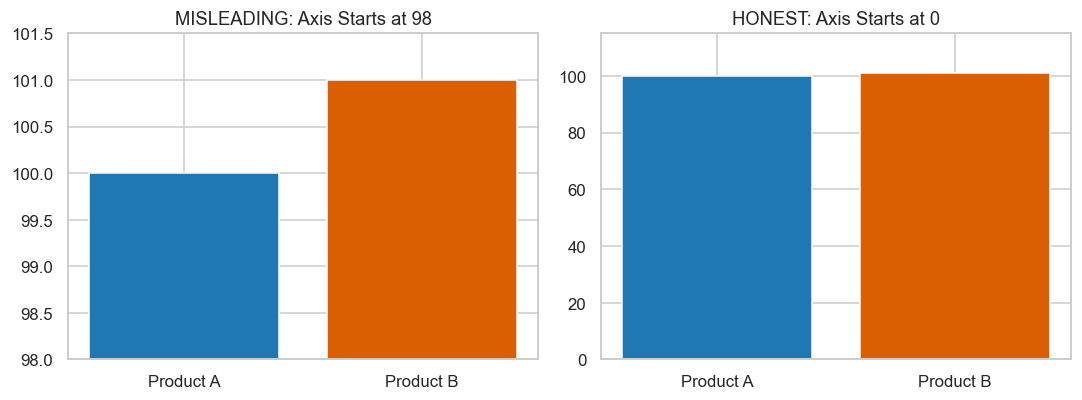

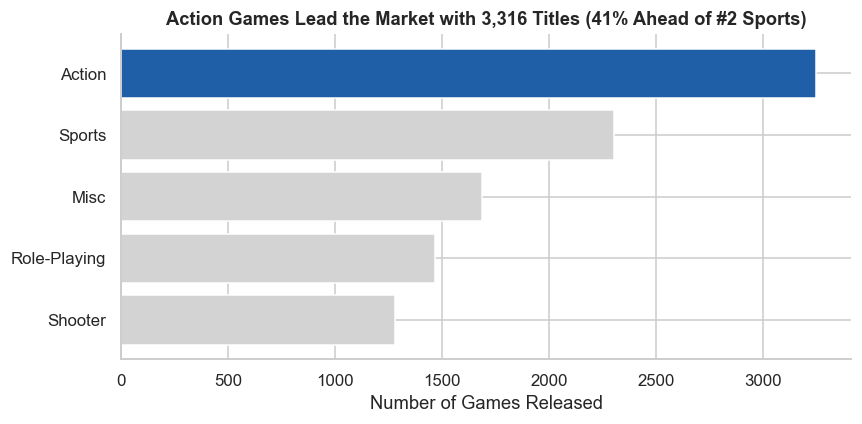

In [6]:
# Demo 1: Honest axes (start at 0) vs Misleading truncated axis
products = ["Product A", "Product B"]
vals = [100, 101]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(products, vals, color=["#1f77b4", "#d95f02"])
axes[0].set_ylim(98, 101.5)
axes[0].set_title("MISLEADING: Axis Starts at 98")

axes[1].bar(products, vals, color=["#1f77b4", "#d95f02"])
axes[1].set_ylim(0, 115)
axes[1].set_title("HONEST: Axis Starts at 0")

plt.tight_layout()
plt.show()

# Demo 2: Highlight ONE key bar, mute the rest in grey + Insight Title
top5_counts = df["Genre"].value_counts().head(5).sort_values()
colors = ["lightgrey" if g != "Action" else "#1f5fa8" for g in top5_counts.index]

plt.figure(figsize=(8, 4))
plt.barh(top5_counts.index, top5_counts.values, color=colors)
plt.title("Action Games Lead the Market with 3,316 Titles (41% Ahead of #2 Sports)", fontsize=12, fontweight="bold")
plt.xlabel("Number of Games Released")
sns.despine()
plt.tight_layout()
plt.show()
